# 16 - FMU plant models next to built-in energysim physics

energysim can co-simulate **FMUs** (Functional Mock-up Units exported from Modelica, Simulink,
Dymola, OpenModelica, ...) with its own Python component models. This notebook uses the two
OpenModelica FMUs that ship with the repository (`examples/optimal_dispatch/`):

* `Hydrogen.ptg_modelB_case2.fmu` - a detailed power-to-gas (PtG) plant: electrolyser, storage,
  controller and an LCOH calculation. Its inputs are `P_order` (power order), `T_ambient`,
  `gas_demand` and `ptg_switch`.
* `P2H.pth_modelB_case2.fmu` - a power-to-heat (PtH) plant: heat pump, boiler, heat storage and an
  LCODH calculation. Its inputs are `P_order`, `T_ambient`, `heat_demand` and `pth_switch`.

We compare the FMU electrolyser with energysim's built-in `AlkalineElectrolyzer`, then combine the
FMU with built-in `H2Compressor` and `H2StorageTank` models. Along the way we meet a real
modelling issue: **FMU variables carry no units**, and one output (`nH2`) has an unknown unit.

**Platform.** FMPy can only run an FMU on a platform that is listed in the FMU archive
(`fmpy.supported_platforms`). These FMUs ship Windows 64-bit binaries (`win64`) and C sources
(`c-code`). On other platforms the FMU sections are skipped with a message.

Everything here is illustrative: the parameters belong to the thesis models, not to a specific
plant. Replace them with datasheet or test data before drawing engineering conclusions.

In [1]:
import struct
import sys
import warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd

from energysim import world
from energysim.models import AlkalineElectrolyzer, H2Compressor, H2StorageTank, ThermalStorageTank
from energysim.models.common.base_component import ModelComponent

try:
    import fmpy
    HAS_FMPY = True
except ImportError:
    HAS_FMPY = False

FMU_NAMES = ("Hydrogen.ptg_modelB_case2.fmu", "P2H.pth_modelB_case2.fmu")


def _find_fmu_dir():
    """The notebook lives in examples/notebooks; the FMUs are in ../optimal_dispatch."""
    for cand in (Path.cwd() / ".." / "optimal_dispatch",
                 Path.cwd() / "examples" / "optimal_dispatch",
                 Path.cwd().parent / "optimal_dispatch"):
        if (cand / FMU_NAMES[0]).is_file():
            return cand.resolve()
    return None


def _platform_tag():
    if sys.platform.startswith("win"):
        return "win64" if struct.calcsize("P") == 8 else "win32"
    if sys.platform.startswith("linux"):
        return "linux64" if struct.calcsize("P") == 8 else "linux32"
    if sys.platform == "darwin":
        return "darwin64"
    return sys.platform


FMU_DIR = _find_fmu_dir()
PLATFORM = _platform_tag()
FMU_OK = False
if HAS_FMPY and FMU_DIR is not None:
    FMU_OK = all(PLATFORM in fmpy.supported_platforms(str(FMU_DIR / f)) for f in FMU_NAMES)

PTG_FMU = str(FMU_DIR / FMU_NAMES[0]) if FMU_DIR else ""
PTH_FMU = str(FMU_DIR / FMU_NAMES[1]) if FMU_DIR else ""

print(f"fmpy installed: {HAS_FMPY}; FMU folder: {FMU_DIR}; platform: {PLATFORM}")
print("FMU sections enabled" if FMU_OK else
      "SKIP: FMU sections need fmpy and a platform listed in the FMU archive "
      f"({PLATFORM!r} not supported by {FMU_NAMES[0]}).")

fmpy installed: True; FMU folder: C:\Users\digvi\Projects\energysim\examples\optimal_dispatch; platform: win64
FMU sections enabled


## 1. Reading the model description, and the missing-units problem

An FMU carries its variables in `modelDescription.xml`. FMPy reads them without running anything.
The `unit` attribute is what energysim uses to convert values between connected simulators (for
example kW to MW). If the attribute is empty, energysim cannot tell whether two values are in the
same unit, so it reports the connection as *unspecified* and passes the number through unchanged.
A silent unit mismatch is the most common error in co-simulation, so we declare units explicitly.

In [2]:
if FMU_OK:
    md = fmpy.read_model_description(PTG_FMU, validate=False)
    print(f"{md.modelName}: FMI {md.fmiVersion}, {len(md.modelVariables)} variables")
    rows = []
    for v in md.modelVariables:
        if v.causality in ("input", "output") or v.name in ("electrolyser_detailed1.nH2",
                                                             "electrolyser_detailed1.Pelec",
                                                             "electrolyser_detailed1.electrochemical.efficiency2"):
            rows.append({"name": v.name, "causality": v.causality, "type": v.type,
                         "unit": v.unit or "(none)", "start": v.start})
    display(pd.DataFrame(rows))
    n_unit = sum(1 for v in md.modelVariables if v.unit)
    print(f"Variables with a declared unit: {n_unit} of {len(md.modelVariables)}")
    print("Outputs are listed with causality 'local' (no 'output' causality), so energysim gets them "
          "by name. The units must come from us.")
else:
    print("SKIP section 1 (FMU not available on this platform).")

Hydrogen.ptg_modelB_case2: FMI 2.0, 265 variables


,name,causality,type,unit,start
0,P_order,input,Real,(none),0.0
1,T_ambient,input,Real,(none),0.0
2,electrolyser_detailed1.nH2,local,Real,(none),None
3,gas_demand,input,Real,(none),0.0
4,ptg_switch,input,Real,(none),0.0
5,electrolyser_detailed1.Pelec,local,Real,(none),None
6,electrolyser_detailed1.electrochemical.efficie...,local,Real,(none),None


Variables with a declared unit: 0 of 265
Outputs are listed with causality 'local' (no 'output' causality), so energysim gets them by name. The units must come from us.


The declarations below are what we know from the model (power in MW, temperatures in degC).
`nH2` is **undeclared**: the thesis model does not say whether it is kmol/s, mol/s or something
else. We therefore keep it dimensionless (`"1"`) and convert it explicitly, with a documented
factor, in section 4. Before trusting any of these numbers, check them against the model
documentation.

In [3]:
PTG_UNITS = {
    "P_order": "MW",
    "T_ambient": "degC",
    "gas_demand": "1",
    "ptg_switch": "1",
    "electrolyser_detailed1.Pelec": "MW",
    "electrolyser_detailed1.nH2": "1",       # UNDECLARED in the FMU - see section 4
    "electrolyser_detailed1.electrochemical.efficiency2": "1",
}

## 2. The detailed electrolyser on its own

We drive the FMU with a staircase of power orders from 10 % to 100 % of a 40 MW nominal plant. Each
level lasts 10 minutes, long enough for the model to settle. We also run the built-in
`AlkalineElectrolyzer` with the same staircase, so both see identical inputs.

Two quantities are compared on a per-unit basis, normalised to their value at nominal load:

* the FMU efficiency `electrochemical.efficiency2` (dimensionless);
* the production per unit of power, `nH2 / Pelec`, for the FMU, and `m_dot_H2 / P_actual` for
  the built-in model. The FMU value is in undeclared units, but a normalised ratio does not
  depend on the unit.

In [4]:
NOM_MW = 40.0
LEVELS_MW = np.arange(4.0, NOM_MW + 1e-9, 4.0)      # 10 % ... 100 % of nominal
LEVEL_S = 600.0
T_STAIR = LEVEL_S * len(LEVELS_MW)


def _staircase(t):
    k = min(int(t // LEVEL_S), len(LEVELS_MW) - 1)
    return float(LEVELS_MW[k])


def _level_end_times():
    """Last recorded time before each step of the staircase (the settled value)."""
    return [(k + 1) * LEVEL_S - 60.0 for k in range(len(LEVELS_MW))]


def run_electrolyser_staircase():
    sim = world(start_time=0, stop_time=T_STAIR, t_macro=60, power_unit="MW")
    sim.add_signal("sched", _staircase, step_size=1, units={"y": "MW"})
    sim.add_signal("tamb", 15.0, step_size=1, units={"y": "degC"})
    sim.add_signal("gas0", 0.0, step_size=1, units={"y": "1"})
    sim.add_signal("ptg_on", 1.0, step_size=1, units={"y": "1"})
    sim.add_fmu("ael_fmu", model=PTG_FMU, step_size=1,
                inputs=["P_order", "T_ambient", "gas_demand", "ptg_switch"],
                outputs=["electrolyser_detailed1.Pelec", "electrolyser_detailed1.nH2",
                         "electrolyser_detailed1.electrochemical.efficiency2"],
                units=PTG_UNITS, validate=False)
    sim.add_model("ael_builtin", AlkalineElectrolyzer(name="ael_builtin", p_nominal_mw=NOM_MW,
                                                       min_turndown_pct=10.0),
                  step_size=1, outputs=["P_actual", "m_dot_H2_kg_hr"])
    sim.add_connections({
        "sched.y": ["ael_fmu.P_order", "ael_builtin.P_cmd"],
        "tamb.y": "ael_fmu.T_ambient",
        "gas0.y": "ael_fmu.gas_demand",
        "ptg_on.y": "ael_fmu.ptg_switch",
    })
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        res = sim.simulate(pbar=False)
    return res


if FMU_OK:
    res_stair = run_electrolyser_staircase()
    df_stair = res_stair.to_frame()
    settled = df_stair.reindex(_level_end_times(), method="ffill").copy()
    settled["load_ratio"] = settled["ael_fmu.electrolyser_detailed1.Pelec"] / NOM_MW
    display(settled[["load_ratio", "ael_fmu.electrolyser_detailed1.Pelec",
                     "ael_fmu.electrolyser_detailed1.nH2",
                     "ael_fmu.electrolyser_detailed1.electrochemical.efficiency2",
                     "ael_builtin.m_dot_H2_kg_hr"]].round(6))
else:
    print("SKIP section 2 (FMU not available on this platform).")

,load_ratio,ael_fmu.electrolyser_detailed1.Pelec,ael_fmu.electrolyser_detailed1.nH2,ael_fmu.electrolyser_detailed1.electrochemical.efficiency2,ael_builtin.m_dot_H2_kg_hr
time,,,,,
540.0,0.1,4.0,0.000348,0.787830,66.494888
1140.0,0.2,8.0,0.000684,0.773177,134.770889
1740.0,0.3,12.0,0.001011,0.761659,204.900538
2340.0,0.4,16.0,0.001330,0.751788,276.960360
2940.0,0.5,20.0,0.001644,0.743293,351.031154
3540.0,0.6,24.0,0.001954,0.736168,427.198291
4140.0,0.7,28.0,0.002262,0.730439,505.552045
4740.0,0.8,32.0,0.002569,0.726077,586.187947
5340.0,0.9,36.0,0.002878,0.722978,669.207175


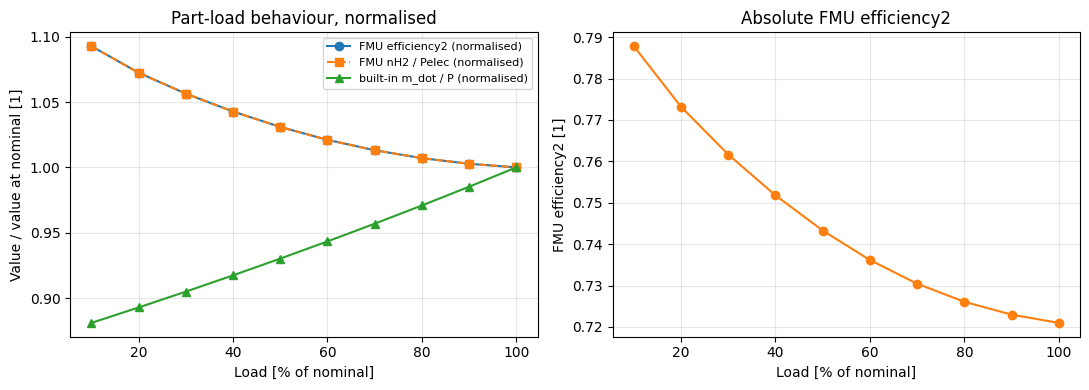

Reading the plot: the thesis FMU is most efficient at low load (efficiency2 falls with load), while the built-in model has a part-load penalty (its specific consumption rises at low load). The two therefore disagree in direction. The FMU describes a stack-level effect; the built-in model describes a plant-level one. Neither is wrong for its purpose, but do not swap them without checking.


In [5]:
if FMU_OK:
    p_fmu = settled["ael_fmu.electrolyser_detailed1.Pelec"].to_numpy()
    nh2 = settled["ael_fmu.electrolyser_detailed1.nH2"].to_numpy()
    eff_fmu = settled["ael_fmu.electrolyser_detailed1.electrochemical.efficiency2"].to_numpy()
    p_bi = settled["ael_builtin.P_actual"].to_numpy()
    h2_bi = settled["ael_builtin.m_dot_H2_kg_hr"].to_numpy()

    ratio_fmu = nh2 / p_fmu
    ratio_bi = h2_bi / (p_bi * 1000.0)            # kg/h per kW
    load = p_fmu / NOM_MW

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(load * 100, eff_fmu / eff_fmu[-1], "o-", label="FMU efficiency2 (normalised)")
    axes[0].plot(load * 100, (ratio_fmu / ratio_fmu[-1]), "s--", label="FMU nH2 / Pelec (normalised)")
    axes[0].plot(load * 100, (ratio_bi / ratio_bi[-1]), "^-", label="built-in m_dot / P (normalised)")
    axes[0].set_xlabel("Load [% of nominal]")
    axes[0].set_ylabel("Value / value at nominal [1]")
    axes[0].set_title("Part-load behaviour, normalised")
    axes[0].grid(alpha=0.3)
    axes[0].legend(fontsize=8)

    axes[1].plot(load * 100, eff_fmu, "o-", color="tab:orange")
    axes[1].set_xlabel("Load [% of nominal]")
    axes[1].set_ylabel("FMU efficiency2 [1]")
    axes[1].set_title("Absolute FMU efficiency2")
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Reading the plot: the thesis FMU is most efficient at low load (efficiency2 falls with load), "
          "while the built-in model has a part-load penalty (its specific consumption rises at low load). "
          "The two therefore disagree in direction. The FMU describes a stack-level effect; the built-in "
          "model describes a plant-level one. Neither is wrong for its purpose, but do not swap them "
          "without checking.")

## 3. Units, once more: what goes wrong without declarations

Without `units=`, energysim knows only the FMU's raw numbers. We rebuild the same world without
declarations and print the unit table, which lists every variable whose unit is still
*unspecified*. The simulation is not run here, so nothing is slowed down.

In [6]:
if FMU_OK:
    sim_nounits = world(start_time=0, stop_time=600, t_macro=60, power_unit="MW")
    sim_nounits.add_signal("sched", 20.0, step_size=1)
    sim_nounits.add_fmu("ael_fmu", model=PTG_FMU, step_size=1,
                        inputs=["P_order"], outputs=["electrolyser_detailed1.Pelec"],
                        validate=False)
    sim_nounits.add_connections({"sched.y": "ael_fmu.P_order"})
    print(sim_nounits.unit_table())
    print("\nWith the declared units from section 1 the same connection is a plain MW to MW link:")
    sim_units = world(start_time=0, stop_time=600, t_macro=60, power_unit="MW")
    sim_units.add_signal("sched", 20.0, step_size=1, units={"y": "MW"})
    sim_units.add_fmu("ael_fmu", model=PTG_FMU, step_size=1,
                      inputs=["P_order"], outputs=["electrolyser_detailed1.Pelec"],
                      units=PTG_UNITS, validate=False)
    sim_units.add_connections({"sched.y": "ael_fmu.P_order"})
    print(sim_units.unit_table())
else:
    print("SKIP section 3 (FMU not available on this platform).")

Connection sched.y -> ael_fmu.P_order: unit of sched.y and ael_fmu.P_order is unspecified; the value is passed through unscaled (declare units={...} or from_unit/to_unit).


Unit system 'energysim-default' [b5362311eccf]
quantity                   default    carrier   accepted units
-------------------------  ---------  --------  --------------
fraction                   1          generic   1, pu, %
active_power               kW         electric  W, kW, MW, GW
reactive_power             kvar       electric  var, kvar, Mvar
apparent_power             kVA        electric  VA, kVA, MVA
voltage                    kV         electric  mV, V, kV, MV
current                    A          electric  mA, A, kA
energy                     kWh        electric  J, kJ, MJ, GJ, Wh, kWh, MWh, GWh
reactive_energy            kvarh      electric  varh, kvarh, Mvarh
frequency                  Hz         electric  Hz, kHz
impedance                  ohm        electric  mohm, ohm, kohm, Mohm
resistance                 ohm        electric  mohm, ohm, kohm, Mohm
voltage_angle              deg        electric  rad, deg
power_factor               1          electric  1, pu, %
volta

## 4. Hybrid plant: FMU electrolyser, built-in compressor and hydrogen storage

Now the electrolyser FMU feeds a *built-in* hydrogen chain:

`FMU electrolyser (nH2)` -> `scaling to kg/h` -> `H2Compressor` -> `H2StorageTank` <- constant demand

### The nH2 scaling factor

`nH2` has no unit, so we choose a scale factor from the **nominal point**. At nominal load
(40 MW) the built-in electrolyser's specific consumption is 53 kWh per kg of H2, so the rate is
`40 000 kW / 53 kWh/kg = 754.7 kg/h`. The FMU reports `nH2 = 0.003164` at that point (section 2).

`factor = 754.7 kg/h / 0.003164 = 238 500 kg/h per unit of nH2`

This is a **calibration**, not a physical conversion: the factor is only valid if the FMU's nH2
is proportional to the hydrogen rate (which the normalised comparison in section 2 suggests). Replace
it with the documented unit as soon as the model owner provides one.

In [7]:
NH2_SPEC_KWH_KG = 53.0
NH2_AT_NOMINAL = 0.003164                       # from section 2 (40 MW point)
NH2_FACTOR_KG_H_PER_UNIT = (NOM_MW * 1000.0 / NH2_SPEC_KWH_KG) / NH2_AT_NOMINAL
print(f"nH2 scale factor: {NH2_FACTOR_KG_H_PER_UNIT:,.0f} kg/h per unit of nH2 "
      f"(calibrated at {NOM_MW:.0f} MW, {NH2_SPEC_KWH_KG} kWh/kg)")


class NH2ToKgPerHour(ModelComponent):
    """Explicit, documented scaling of the FMU's undeclared nH2 output to kg/h.

    ``m_dot_kg_hr = factor * nH2_raw``. The factor is a calibration constant chosen at the
    nominal point (see the notebook), not a physical unit conversion.
    """

    units = {"nH2_raw": "1", "m_dot_kg_hr": "kg/h"}

    def __init__(self, name="nH2_scale", factor=1.0, **kwargs):
        super().__init__(name=name, **kwargs)
        self.factor = float(factor)
        self.register_variables(inputs=["nH2_raw"], outputs=["m_dot_kg_hr"])
        self.register_parameters("factor")

    def step_model(self, dt: float, time: float) -> None:
        raw = float(self._inputs_val.get("nH2_raw", 0.0))
        self._outputs_val["m_dot_kg_hr"] = self.factor * raw

nH2 scale factor: 238,533 kg/h per unit of nH2 (calibrated at 40 MW, 53.0 kWh/kg)


In [8]:
# A 24 h winter profile for the electrolyser power order (wind-like, deterministic)
rng = np.random.default_rng(16)
HOURS = np.arange(25) * 3600.0
_base = 0.45 + 0.35 * np.sin(2 * np.pi * (HOURS / 86400.0) * 1.0 + 0.8)
_gust = rng.uniform(-0.15, 0.15, size=HOURS.size)
P_ORDER_HOURLY = 40.0 * np.clip(_base + _gust, 0.12, 1.0)

def p_order_profile(t):
    return float(np.interp(t, HOURS, P_ORDER_HOURLY))

H2_DEMAND_KG_H = 350.0

def build_hybrid_world(t_end=86400.0):
    sim = world(start_time=0, stop_time=t_end, t_macro=900, power_unit="MW")
    sim.add_signal("power", p_order_profile, step_size=900, units={"y": "MW"})
    sim.add_signal("tamb", 15.0, step_size=900, units={"y": "degC"})
    sim.add_signal("gas0", 0.0, step_size=900, units={"y": "1"})
    sim.add_signal("ptg_on", 1.0, step_size=900, units={"y": "1"})
    sim.add_signal("h2_demand", H2_DEMAND_KG_H, step_size=900, units={"y": "kg/h"})
    sim.add_fmu("ptg", model=PTG_FMU, step_size=1,
                inputs=["P_order", "T_ambient", "gas_demand", "ptg_switch"],
                outputs=["electrolyser_detailed1.Pelec", "electrolyser_detailed1.nH2",
                         "electrolyser_detailed1.electrochemical.efficiency2"],
                units=PTG_UNITS, validate=False)
    sim.add_model("scale", NH2ToKgPerHour(name="scale", factor=NH2_FACTOR_KG_H_PER_UNIT),
                  step_size=900, outputs=["m_dot_kg_hr"])
    sim.add_model("comp", H2Compressor(name="comp", max_flow_kg_hr=1500.0), step_size=900,
                  outputs=["m_dot_out_kg_hr", "P_elec_kW"])
    sim.add_model("tank", H2StorageTank(name="tank", volume_m3=200.0, p_max_bar=350.0,
                                        p_min_bar=20.0, p_init_bar=150.0),
                  step_size=900, outputs=["pressure_bar", "mass_stored_kg", "SoC"])
    sim.add_connections({
        "power.y": "ptg.P_order",
        "tamb.y": "ptg.T_ambient",
        "gas0.y": "ptg.gas_demand",
        "ptg_on.y": "ptg.ptg_switch",
        "ptg.electrolyser_detailed1.nH2": "scale.nH2_raw",
        "scale.m_dot_kg_hr": "comp.m_dot_in_kg_hr",
        "comp.m_dot_out_kg_hr": "tank.m_dot_in_kg_hr",
        "h2_demand.y": "tank.m_dot_out_kg_hr",
    })
    return sim


if FMU_OK:
    sim_h = build_hybrid_world()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        res_h = sim_h.simulate(pbar=False)
    df_h = res_h.to_frame()
    hours = df_h.index.to_numpy() / 3600.0

    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
    axes[0].plot(hours, df_h["power.y"], label="power order")
    axes[0].plot(hours, df_h["ptg.electrolyser_detailed1.Pelec"], "--", label="FMU Pelec")
    axes[0].set_ylabel("Power [MW]")
    axes[0].legend(fontsize=8)
    axes[1].plot(hours, df_h["scale.m_dot_kg_hr"], label="H2 production (scaled)")
    axes[1].plot(hours, df_h["comp.m_dot_out_kg_hr"], "--", label="compressor out")
    axes[1].axhline(H2_DEMAND_KG_H, color="k", lw=0.8, label="demand")
    axes[1].set_ylabel("H2 flow [kg/h]")
    axes[1].legend(fontsize=8)
    axes[2].plot(hours, df_h["tank.pressure_bar"], color="tab:purple")
    axes[2].set_ylabel("Tank pressure [bar]")
    axes[2].set_xlabel("Time [h]")
    fig.suptitle("Hybrid PtG: FMU electrolyser + built-in compressor and H2 tank")
    plt.tight_layout()
    plt.show()
    print(f"Tank SoC range: {df_h['tank.SoC'].min():.2f} .. {df_h['tank.SoC'].max():.2f}")
else:
    print("SKIP section 4 (FMU not available on this platform).")

FMICallException: fmi2DoStep failed with status 3 (error).

## 5. Optional: the power-to-heat FMU with a built-in thermal store

The power-to-heat FMU reports electric power (`hp2.Pelec`), a dimensionless COP (`hp2.COP`) and several
heat outputs (`hp2.Q`, `hp2.Qhp`, `hp2.Qtotal`, ...). A heat output must be consistent with the
electric power: heat = COP x electric power, in the same unit system. The check below tests that for
the FMU's own heat outputs, and it does **not** hold: the ratio of `hp2.Qhp` to COP x `hp2.Pelec` is a
large, load-dependent number, so the heat outputs have undeclared, inconsistent units.

We therefore use only the trustworthy outputs (electric power and COP). A small `ModelComponent`
computes the heat as COP x P_elec, and a built-in `ThermalStorageTank` stores the surplus over a
time-varying heat demand. Check the FMU's heat definition with the model owner before you rely on it.

FMU hp2.Qhp / (COP x Pelec) = 3,942  (a consistent MW output would give 1)
So the FMU's heat outputs are not usable without their unit. This section uses COP x Pelec.


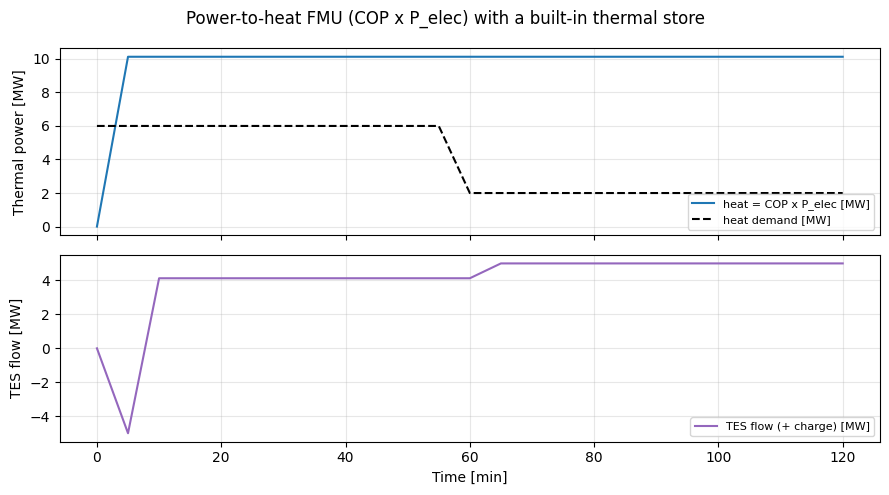

In [9]:
PTH_UNITS = {
    "P_order": "MW", "T_ambient": "degC", "heat_demand": "MW", "pth_switch": "1",
    "hp2.Pelec": "MW", "hp2.COP": "1",
    "hp2.Q": "1", "hp2.Qhp": "1", "hp2.Qtotal": "1",    # undeclared heat outputs - not used
    "storage.S": "1",
}


class HeatFromCOP(ModelComponent):
    """Heat from electric power and COP: Q_heat = COP * P_elec (both in MW)."""

    units = {"P_elec_MW": "MW", "COP": "1", "Q_heat_MW": "MW"}

    def __init__(self, name="heat_from_cop", step_size=300.0, **kwargs):
        super().__init__(name=name, step_size=step_size, **kwargs)
        self.register_variables(inputs=["P_elec_MW", "COP"], outputs=["Q_heat_MW"],
                                defaults={"P_elec_MW": 0.0, "COP": 1.0})

    def step_model(self, dt: float, time: float) -> None:
        p = float(self._inputs_val.get("P_elec_MW", 0.0))
        cop = float(self._inputs_val.get("COP", 1.0))
        self._outputs_val["Q_heat_MW"] = cop * p


def pth_heat_demand_mw(t):
    """Heat demand [MW]: 6 MW in the first hour (deficit), 2 MW in the second (surplus)."""
    return 6.0 if t < 3600.0 else 2.0


if FMU_OK:
    sim_p2h = world(start_time=0, stop_time=7200, t_macro=300, power_unit="MW")
    sim_p2h.add_signal("p_ord", 2.0, step_size=300, units={"y": "MW"})
    sim_p2h.add_signal("tamb", 0.0, step_size=300, units={"y": "degC"})
    sim_p2h.add_signal("hdem", pth_heat_demand_mw, step_size=300, units={"y": "MW"})
    sim_p2h.add_signal("neg_hdem", lambda t: -pth_heat_demand_mw(t), step_size=300, units={"y": "MW"})
    sim_p2h.add_signal("pth_on", 1.0, step_size=300, units={"y": "1"})
    sim_p2h.add_fmu("pth", model=PTH_FMU, step_size=300,
                    inputs=["P_order", "T_ambient", "heat_demand", "pth_switch"],
                    outputs=["hp2.Pelec", "hp2.COP", "hp2.Qhp", "hp2.Q", "storage.S"],
                    units=PTH_UNITS, validate=False)
    sim_p2h.add_model("heat", HeatFromCOP(name="heat", step_size=300.0), step_size=300,
                      outputs=["Q_heat_MW"])
    sim_p2h.add_model("tes", ThermalStorageTank(name="tes", capacity_mwh_th=20.0,
                                                max_flow_rate_mw_th=5.0, soc_init=0.5),
                      step_size=300, outputs=["SoC", "Q_actual_MW"])
    sim_p2h.add_connections({
        "p_ord.y": "pth.P_order",
        "tamb.y": "pth.T_ambient",
        "hdem.y": "pth.heat_demand",
        "pth_on.y": "pth.pth_switch",
        "pth.hp2.Pelec": "heat.P_elec_MW",
        "pth.hp2.COP": "heat.COP",
        ("heat.Q_heat_MW", "neg_hdem.y"): "tes.Q_cmd_MW",
    })
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        res_p2h = sim_p2h.simulate(pbar=False)
    df_p2h = res_p2h.to_frame()
    last = df_p2h.iloc[-1]
    ratio = last["pth.hp2.Qhp"] / (last["pth.hp2.COP"] * last["pth.hp2.Pelec"])
    print(f"FMU hp2.Qhp / (COP x Pelec) = {ratio:,.0f}  (a consistent MW output would give 1)")
    print("So the FMU's heat outputs are not usable without their unit. This section uses COP x Pelec.")
    h = df_p2h.index.to_numpy() / 60.0
    fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    axes[0].plot(h, df_p2h["heat.Q_heat_MW"], label="heat = COP x P_elec [MW]")
    axes[0].plot(h, [pth_heat_demand_mw(t * 60.0) for t in h], "k--", label="heat demand [MW]")
    axes[0].set_ylabel("Thermal power [MW]")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)
    axes[1].plot(h, df_p2h["tes.Q_actual_MW"], color="tab:purple", label="TES flow (+ charge) [MW]")
    axes[1].set_ylabel("TES flow [MW]")
    axes[1].set_xlabel("Time [min]")
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)
    fig.suptitle("Power-to-heat FMU (COP x P_elec) with a built-in thermal store")
    plt.tight_layout()
    plt.show()
else:
    print("SKIP section 5 (FMU not available on this platform).")

## 6. Bring your own FMU

An FMU is a zip file with a `modelDescription.xml` and compiled binaries. To use your own model:

1. **Export.** In OpenModelica, Dymola or Simulink choose *Export FMU* and select **FMI 2.0
   Co-Simulation**. Set the communication step (for example 60 s) and select the inputs and outputs
   you need, typically with `causality = input` / `output`. Give every variable a unit in the
   model (`Modelica.Units.SI.Power` and similar types declare units automatically; plain `Real`
   does not).
2. **Check.** Run `fmpy.read_model_description(path)` and confirm the inputs and outputs and their
   `unit` attributes. Check `fmpy.supported_platforms(path)` for your platform (`win64`, `linux64`).
3. **Plug in.** Call `sim.add_fmu("name", model=path, step_size=..., inputs=[...], outputs=[...],
   units={...})`. Declare a unit for every connected variable, and use the exact variable names from
   the model description (dotted names for components).
4. **Unknown units.** If a unit is genuinely unknown, keep it dimensionless (`"1"`), calibrate a
   documented factor at a reference point (as in section 4), and record that factor next to the model.

Co-simulation FMUs run at their own communication step, so use the same step (or a multiple) for the
`add_fmu` `step_size`. Model-exchange FMUs are also supported, but they are slower.

## Where to go next

* **13 - District heat, houses and an electric feeder**: a sector-coupled case that couples a heat
  network and an OpenDSS feeder.
* **15 - Curves and 2-D maps with grid solvers**: volt-var / volt-watt inverter control, COP
  maps and dynamic line rating.
* **07 - Green hydrogen valley**: a larger hydrogen case using the built-in chain.
* **03 - Custom models and parametrization**: how to write your own `ModelComponent` such as
  `NH2ToKgPerHour` above.